# ***First implementation of VIT with random values ​​of parameters***

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [ ]:
# 2. Data set preparation
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 9912422/9912422 [00:01<00:00, 6062523.23it/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 28881/28881 [00:00<00:00, 159108.75it/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 1648877/1648877 [00:01<00:00, 1508731.28it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 4542/4542 [00:00<00:00, 9011603.01it/s]

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



In [ ]:
# 3. Model Implementation
class PatchEmbedding(nn.Module):
    def __init__(self, image_size, patch_size, in_channels, embed_dim):
        super().__init__()
        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.proj(x)  # (B, embed_dim, H', W')
        x = x.flatten(2)  # (B, embed_dim, H'*W')
        x = x.transpose(1, 2)  # (B, H'*W', embed_dim)
        return x

class VisionTransformer(nn.Module):
    def __init__(self, image_size, patch_size, num_classes, dim, depth, heads, mlp_dim):
        super().__init__()
        self.patch_embed = PatchEmbedding(image_size, patch_size, 1, dim)
        num_patches = self.patch_embed.num_patches

        self.cls_token = nn.Parameter(torch.randn(1, 1, dim)) # Initializes cls token random with normal distribution
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches + 1, dim)) # Initializes position embeddings with random values from a normal distribution
        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model=dim, nhead=heads, dim_feedforward=mlp_dim),
            num_layers=depth
        )
        self.mlp_head = nn.Linear(dim, num_classes)

    def forward(self, x): # x is input image size
        x = self.patch_embed(x) #Converts the image into patch embeddings
        b, n, _ = x.shape  #Extracts the batch size and number of patches

        cls_tokens = self.cls_token.expand(b, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1) #is used to concatenate the class token to the sequence of patch embeddings along a specific dimension
        x += self.pos_embed   #adding possistion info to tokens

        x = self.transformer(x) # x is an tensor that include patches token + cls token
        x = x[:, 0]  # Take the cls token representation and Extracting the Class Token Representation

        return self.mlp_head(x) #maps the class token representation to the number of output classes.

# Model initialization
model = VisionTransformer(
    image_size = 28,
    patch_size = 4,
    num_classes = 10,
    dim = 256,
    depth = 6,
    heads = 8,
    mlp_dim = 512
)

/usr/local/lib/python3.10/dist-packages/torch/nn/modules/transformer.py:306: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Epoch 1/10:
Train Loss: 2.3240, Train Acc: 10.25%
Test Loss: 2.3137, Test Acc: 11.35%
Epoch 2/10:
Train Loss: 2.3079, Train Acc: 10.37%
Test Loss: 2.3066, Test Acc: 10.28%
Epoch 3/10:
Train Loss: 2.3042, Train Acc: 10.70%
Test Loss: 2.3042, Test Acc: 11.35%
Epoch 4/10:
Train Loss: 2.3032, Train Acc: 10.81%
Test Loss: 2.3023, Test Acc: 11.35%
Epoch 5/10:
Train Loss: 2.3027, Train Acc: 10.87%
Test Loss: 2.3021, Test Acc: 11.35%
Epoch 6/10:
Train Loss: 2.3025, Train Acc: 10.98%
Test Loss: 2.3015, Test Acc: 11.35%
Epoch 7/10:
Train Loss: 2.3024, Train Acc: 10.91%
Test Loss: 2.3019, Test Acc: 11.35%
Epoch 8/10:
Train Loss: 2.3022, Train Acc: 11.11%
Test Loss: 2.3014, Test Acc: 11.35%
Epoch 9/10:
Train Loss: 2.3022, Train Acc: 10.92%
Test Loss: 2.3016, Test Acc: 11.35%
Epoch 10/10:
Train Loss: 2.3020, Train Acc: 11.02%
Test Loss: 2.3014, Test Acc: 11.35%


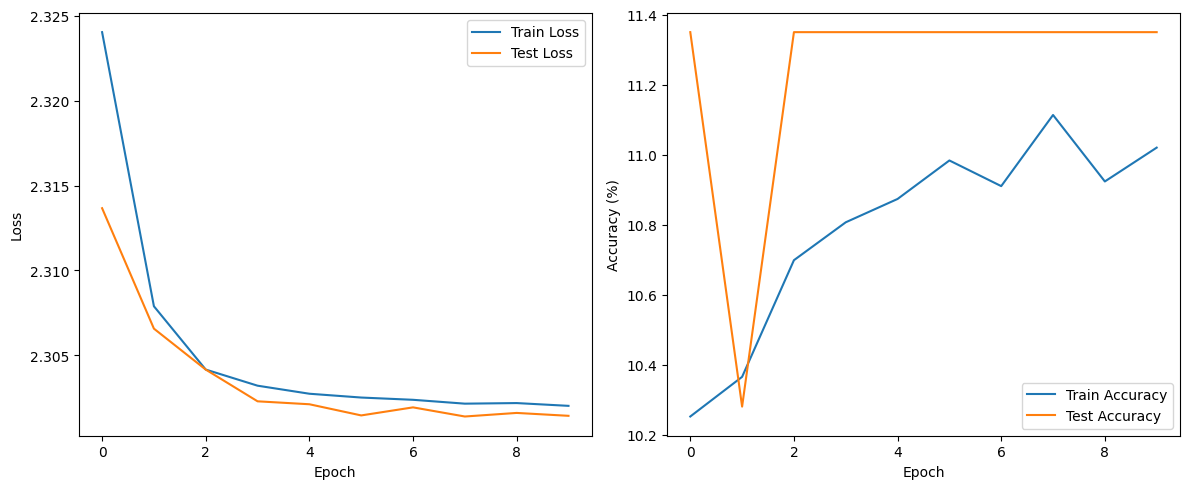

In [ ]:
# 4. Learning and evaluating
def train(model, train_loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = output.max(1)
        total += target.size(0)
        correct += predicted.eq(target).sum().item()

    return total_loss / len(train_loader), 100. * correct / total

def test(model, test_loader, criterion, device):
    model.eval()
    test_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += criterion(output, target).item()
            _, predicted = output.max(1)
            total += target.size(0)
            correct += predicted.eq(target).sum().item()

    return test_loss / len(test_loader), 100. * correct / total

# Training loop
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10
train_losses, train_accs, test_losses, test_accs = [], [], [], []

for epoch in range(epochs):
    train_loss, train_acc = train(model, train_loader, optimizer, criterion, device)
    test_loss, test_acc = test(model, test_loader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    print(f'Epoch {epoch+1}/{epochs}:')
    print(f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%')
    print(f'Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}%')

# Plotting
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(test_accs, label='Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

# ***Another implementation to enhance accuracy by define hyperparameter search function***

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, SubsetRandomSampler
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import itertools

In [ ]:
# Vision Transformer Model
class ViT(nn.Module):
    def __init__(self, image_size, patch_size, num_classes, dim, depth, heads, mlp_dim, pool='cls', channels=1):
        super().__init__()
        assert image_size % patch_size == 0, 'Image dimensions must be divisible by the patch size.'
        num_patches = (image_size // patch_size) ** 2
        patch_dim = channels * patch_size ** 2

        self.patch_size = patch_size

        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches + 1, dim))
        self.patch_to_embedding = nn.Linear(patch_dim, dim)
        self.cls_token = nn.Parameter(torch.randn(1, 1, dim))
        self.transformer = Transformer(dim, depth, heads, mlp_dim)

        self.pool = pool
        self.to_latent = nn.Identity()

        self.mlp_head = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, num_classes)
        )

    def forward(self, img):
        p = self.patch_size

        x = img.unfold(2, p, p).unfold(3, p, p).reshape(img.size(0), -1, p*p*img.size(1))
        x = self.patch_to_embedding(x)
        b, n, _ = x.shape

        cls_tokens = self.cls_token.expand(b, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x += self.pos_embedding[:, :(n + 1)]
        x = self.transformer(x)

        x = x.mean(dim = 1) if self.pool == 'mean' else x[:, 0]

        x = self.to_latent(x)
        return self.mlp_head(x)

class Transformer(nn.Module):
    def __init__(self, dim, depth, heads, mlp_dim):
        super().__init__()
        self.layers = nn.ModuleList([])
        for _ in range(depth):
            self.layers.append(nn.ModuleList([
                PreNorm(dim, Attention(dim, heads = heads)),
                PreNorm(dim, FeedForward(dim, mlp_dim))
            ]))

    def forward(self, x):
        for attn, ff in self.layers:
            x = attn(x) + x
            x = ff(x) + x
        return x

class PreNorm(nn.Module):
    def __init__(self, dim, fn):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fn = fn
    def forward(self, x, **kwargs):
        return self.fn(self.norm(x), **kwargs)

class FeedForward(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, dim)
        )
    def forward(self, x):
        return self.net(x)

class Attention(nn.Module):
    def __init__(self, dim, heads = 8):
        super().__init__()
        self.heads = heads
        self.scale = dim ** -0.5

        self.to_qkv = nn.Linear(dim, dim * 3, bias = False)
        self.to_out = nn.Linear(dim, dim)

    def forward(self, x):
        b, n, _, h = *x.shape, self.heads
        qkv = self.to_qkv(x).chunk(3, dim = -1)
        q, k, v = map(lambda t: t.reshape(b, n, h, -1).transpose(1, 2), qkv)

        dots = torch.matmul(q, k.transpose(-1, -2)) * self.scale
        attn = dots.softmax(dim=-1)

        out = torch.matmul(attn, v)
        out = out.transpose(1, 2).reshape(b, n, -1)
        out =  self.to_out(out)
        return out

In [ ]:
# Training function
def train(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(dataloader)
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc

# Testing function
def test(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(dataloader)
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc

In [ ]:
# Hyperparameter search function
def hyperparameter_search(train_dataset, test_dataset, device, num_epochs=5):
    # Define the hyperparameter grid
    param_grid = {
        'patch_size': [4, 7],
        'dim': [128, 256],
        'depth': [4, 6],
        'heads': [4, 8],
        'mlp_dim': [256, 512],
        'learning_rate': [0.001, 0.01]
    }

    # Create all possible combinations of hyperparameters
    param_combinations = list(itertools.product(*param_grid.values()))

    # Use a subset of the training data for faster hyperparameter search
    subset_size = 10000
    subset_indices = torch.randperm(len(train_dataset))[:subset_size]
    subset_sampler = SubsetRandomSampler(subset_indices)
    subset_loader = DataLoader(train_dataset, batch_size=64, sampler=subset_sampler)

    best_acc = 0
    best_params = {}

    for params in tqdm(param_combinations, desc="Hyperparameter Search"):
        patch_size, dim, depth, heads, mlp_dim, lr = params

        # Create and initialize the model
        model = ViT(
            image_size=28,
            patch_size=patch_size,
            num_classes=10,
            dim=dim,
            depth=depth,
            heads=heads,
            mlp_dim=mlp_dim
        ).to(device)

        optimizer = optim.Adam(model.parameters(), lr=lr)
        criterion = nn.CrossEntropyLoss()

        # Train the model
        for epoch in range(num_epochs):
            train(model, subset_loader, optimizer, criterion, device)

        # Evaluate the model
        test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
        _, test_acc = test(model, test_loader, criterion, device)

        # Update best parameters if necessary
        if test_acc > best_acc:
            best_acc = test_acc
            best_params = {
                'patch_size': patch_size,
                'dim': dim,
                'depth': depth,
                'heads': heads,
                'mlp_dim': mlp_dim,
                'learning_rate': lr
            }

        # Free up memory
        del model
        torch.cuda.empty_cache()

    print(f"Best accuracy: {best_acc:.2f}%")
    print(f"Best parameters: {best_params}")

    return best_params, best_acc

# ***Show best acc and best hyperparameter that function found then plot their influence***

Hyperparameter Search: 100%|██████████| 64/64 [25:16<00:00, 23.69s/it]


Best accuracy: 95.85%
Best parameters: {'patch_size': 7, 'dim': 128, 'depth': 6, 'heads': 4, 'mlp_dim': 256, 'learning_rate': 0.001}


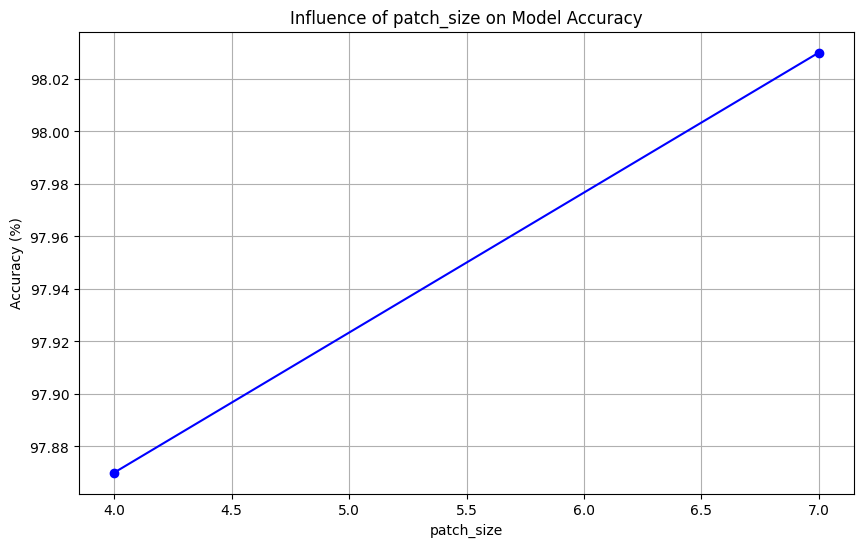

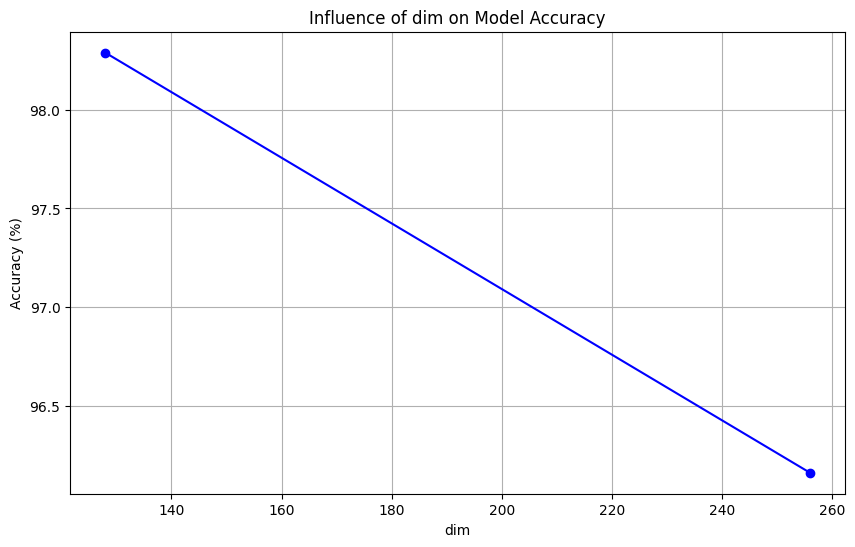

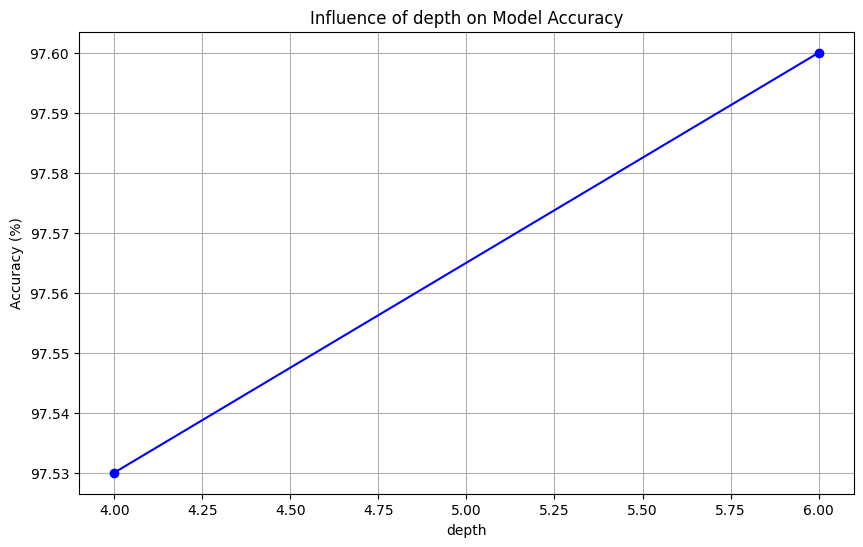

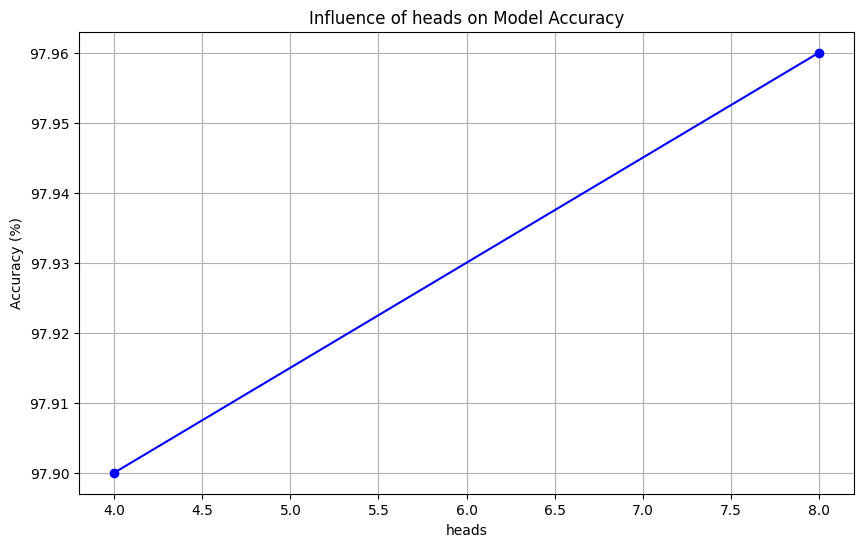

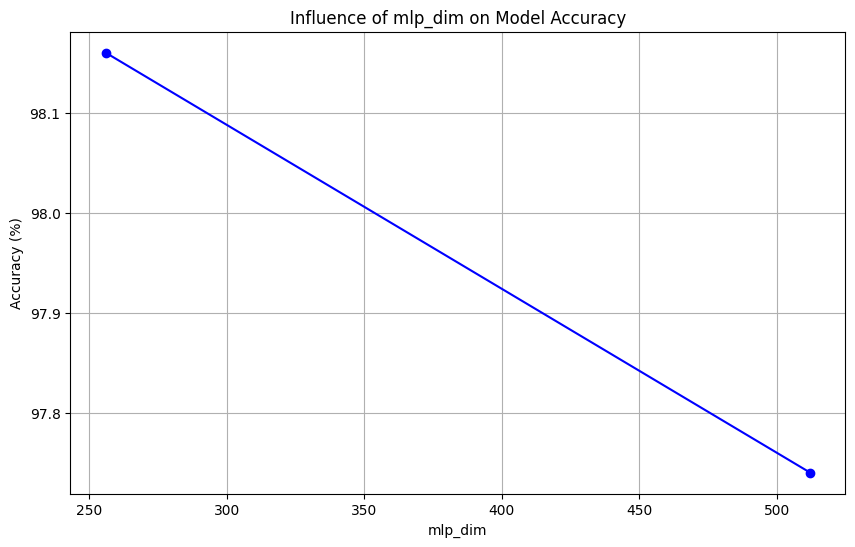

In [ ]:
# Visualization of hyperparameter search results
def plot_hyperparameter_influence(param_name, param_values, accuracies):
    plt.figure(figsize=(10, 6))
    plt.plot(param_values, accuracies, 'bo-')
    plt.xlabel(param_name)
    plt.ylabel('Accuracy (%)')
    plt.title(f'Influence of {param_name} on Model Accuracy')
    plt.grid(True)
    plt.show()

# Main execution
if __name__ == "__main__":
    # Set up MNIST dataset
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Perform hyperparameter search
    best_params, best_acc = hyperparameter_search(train_dataset, test_dataset, device)

    # Analyze influence of each hyperparameter
    param_grid = {
        'patch_size': [4, 7],
        'dim': [128, 256],
        'depth': [4, 6],
        'heads': [4, 8],
        'mlp_dim': [256, 512],
        'learning_rate': [0.001, 0.01]
    }

    for param_name in best_params.keys():
        if param_name != 'learning_rate':
            param_values = param_grid[param_name]
            accuracies = []
            for value in param_values:
                params = best_params.copy()
                params[param_name] = value
                lr = params.pop('learning_rate')
                model = ViT(image_size=28, num_classes=10, **params).to(device)
                optimizer = optim.Adam(model.parameters(), lr=lr)
                criterion = nn.CrossEntropyLoss()
                train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
                test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
                for _ in range(5):  # Train for 5 epochs
                    train(model, train_loader, optimizer, criterion, device)
                _, acc = test(model, test_loader, criterion, device)
                accuracies.append(acc)
            plot_hyperparameter_influence(param_name, param_values, accuracies)

# ***cheking influence of learning rate parameter in acc***

Testing Learning Rates: 100%|██████████| 6/6 [12:34<00:00, 125.77s/it]


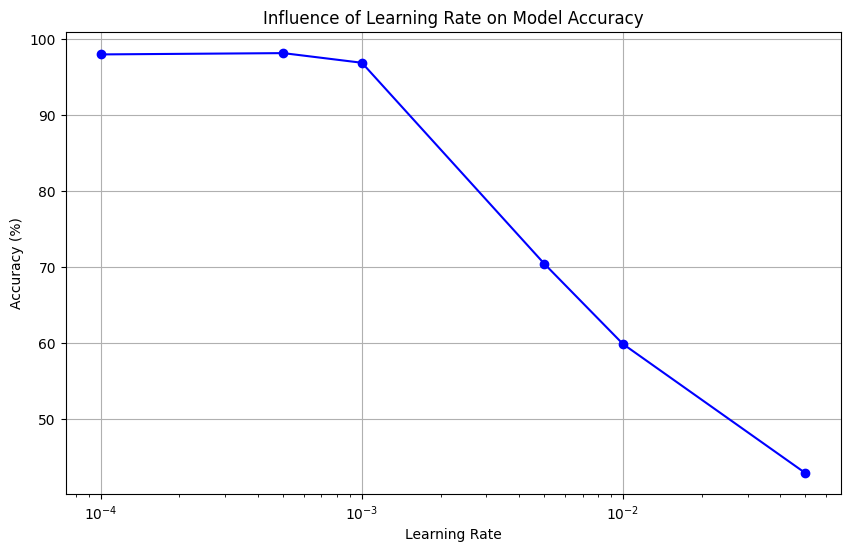

In [ ]:
def plot_learning_rate_influence(train_dataset, test_dataset, device, best_params, num_epochs=5):
    # Define the learning rate values to test
    learning_rates = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05]
    accuracies = []

    # Prepare data loaders
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

    for lr in tqdm(learning_rates, desc="Testing Learning Rates"):
        # Create model with best parameters
        model = ViT(
            image_size=28,
            patch_size=best_params['patch_size'],
            num_classes=10,
            dim=best_params['dim'],
            depth=best_params['depth'],
            heads=best_params['heads'],
            mlp_dim=best_params['mlp_dim']
        ).to(device)

        optimizer = optim.Adam(model.parameters(), lr=lr)
        criterion = nn.CrossEntropyLoss()

        # Train the model
        for epoch in range(num_epochs):
            train(model, train_loader, optimizer, criterion, device)

        # Test the model
        _, acc = test(model, test_loader, criterion, device)
        accuracies.append(acc)

        # Free up memory
        del model
        torch.cuda.empty_cache()

    # Create the plot
    plt.figure(figsize=(10, 6))
    plt.semilogx(learning_rates, accuracies, 'bo-')
    plt.xlabel('Learning Rate')
    plt.ylabel('Accuracy (%)')
    plt.title('Influence of Learning Rate on Model Accuracy')
    plt.grid(True)
    plt.show()

# Main execution
if __name__ == "__main__":
    # Set up MNIST dataset
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Assume we have already performed hyperparameter search and have best_params
    best_params = {
        'patch_size': 7,
        'dim': 256,
        'depth': 6,
        'heads': 8,
        'mlp_dim': 512,
        'learning_rate': 0.001  # This will be varied in our plot
    }

    # Create the learning rate influence plot
    plot_learning_rate_influence(train_dataset, test_dataset, device, best_params)

# ***Train VIT with best hyperparameter and show acc & loss by lr = 0.001***

Training Progress:   2%|▏         | 1/50 [00:26<21:56, 26.86s/it]

Epoch [1/50], Train Loss: 0.2673, Train Acc: 91.45%, Test Loss: 0.1232, Test Acc: 96.11%


Training Progress:   4%|▍         | 2/50 [00:54<21:51, 27.32s/it]

Epoch [2/50], Train Loss: 0.0995, Train Acc: 96.89%, Test Loss: 0.0881, Test Acc: 97.25%


Training Progress:   6%|▌         | 3/50 [01:22<21:36, 27.58s/it]

...

Epoch [48/50], Train Loss: 0.0075, Train Acc: 99.74%, Test Loss: 0.0591, Test Acc: 98.60%


Training Progress:  98%|█████████▊| 49/50 [22:26<00:27, 27.02s/it]

Epoch [49/50], Train Loss: 0.0082, Train Acc: 99.72%, Test Loss: 0.0557, Test Acc: 98.69%


Training Progress: 100%|██████████| 50/50 [22:52<00:00, 27.45s/it]

Epoch [50/50], Train Loss: 0.0044, Train Acc: 99.87%, Test Loss: 0.0488, Test Acc: 98.90%


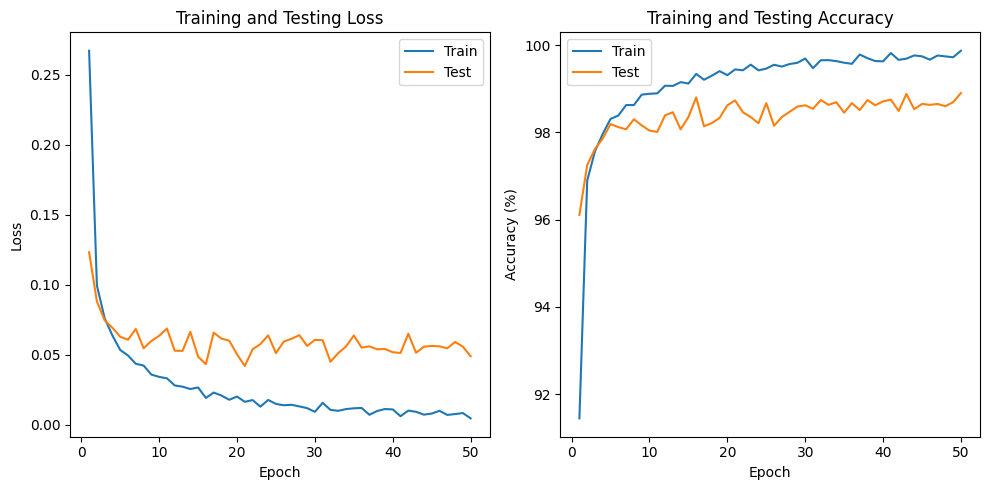

In [ ]:
def train_and_plot(model, train_loader, test_loader, optimizer, criterion, device, num_epochs=50):
    train_losses = []
    train_accuracies = []
    test_losses = []
    test_accuracies = []

    for epoch in tqdm(range(num_epochs), desc="Training Progress"):
        # Train
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = outputs.max(1)
            train_total += labels.size(0)
            train_correct += predicted.eq(labels).sum().item()

        train_loss = train_loss / len(train_loader)
        train_accuracy = 100. * train_correct / train_total
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        # Test
        model.eval()
        test_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                test_loss += loss.item()
                _, predicted = outputs.max(1)
                test_total += labels.size(0)
                test_correct += predicted.eq(labels).sum().item()

        test_loss = test_loss / len(test_loader)
        test_accuracy = 100. * test_correct / test_total
        test_losses.append(test_loss)
        test_accuracies.append(test_accuracy)

        print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, '
              f'Test Loss: {test_loss:.4f}, Test Acc: {test_accuracy:.2f}%')

    # Plot training and testing loss
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.plot(range(1, num_epochs+1), train_losses, label='Train')
    plt.plot(range(1, num_epochs+1), test_losses, label='Test')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Testing Loss')
    plt.legend()

    # Plot training and testing accuracy
    plt.subplot(1, 2, 2)
    plt.plot(range(1, num_epochs+1), train_accuracies, label='Train')
    plt.plot(range(1, num_epochs+1), test_accuracies, label='Test')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Training and Testing Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Main execution
if __name__ == "__main__":
    # Set up MNIST dataset
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create model (using the best parameters you found from hyperparameter search)
    model = ViT(
        image_size=28,
        patch_size=7,
        num_classes=10,
        dim=128,
        depth=6,
        heads=4,
        mlp_dim=256
    ).to(device)

    # Set up optimizer and loss function
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # Train the model and create plots
    train_and_plot(model, train_loader, test_loader, optimizer, criterion, device, num_epochs=50)

# ***if lr = 0.0001***

Training Progress:   2%|▏         | 1/50 [00:27<22:46, 27.88s/it]

Epoch [1/50], Train Loss: 0.5030, Train Acc: 84.42%, Test Loss: 0.1747, Test Acc: 95.03%


Training Progress:   4%|▍         | 2/50 [00:54<21:55, 27.40s/it]

Epoch [2/50], Train Loss: 0.1434, Train Acc: 95.80%, Test Loss: 0.1306, Test Acc: 95.95%


Training Progress:   6%|▌         | 3/50 [01:21<21:05, 26.93s/it]

...

Epoch [48/50], Train Loss: 0.0000, Train Acc: 100.00%, Test Loss: 0.0619, Test Acc: 98.85%


Training Progress:  98%|█████████▊| 49/50 [21:46<00:26, 26.67s/it]

Epoch [49/50], Train Loss: 0.0000, Train Acc: 100.00%, Test Loss: 0.0638, Test Acc: 98.84%


Training Progress: 100%|██████████| 50/50 [22:13<00:00, 26.66s/it]

Epoch [50/50], Train Loss: 0.0000, Train Acc: 100.00%, Test Loss: 0.0656, Test Acc: 98.85%


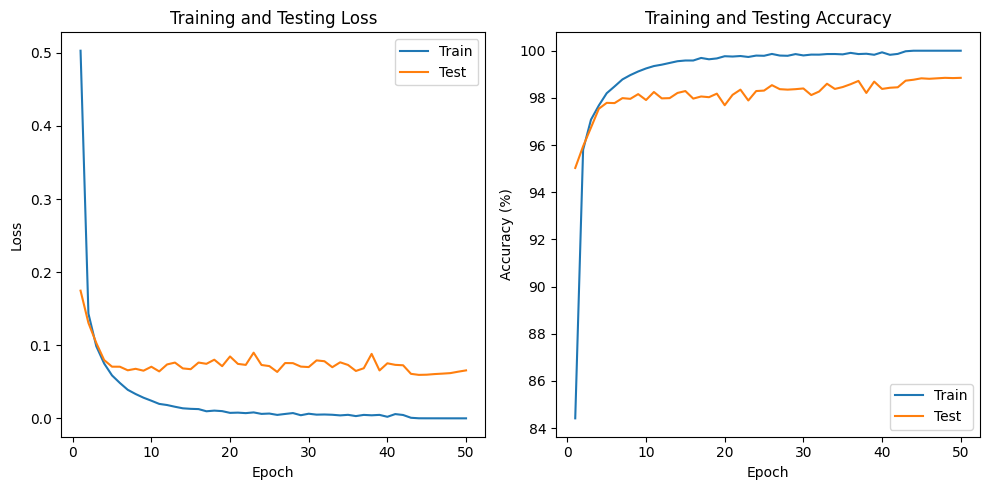

In [ ]:
def train_and_plot(model, train_loader, test_loader, optimizer, criterion, device, num_epochs=50):
    train_losses = []
    train_accuracies = []
    test_losses = []
    test_accuracies = []

    for epoch in tqdm(range(num_epochs), desc="Training Progress"):
        # Train
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = outputs.max(1)
            train_total += labels.size(0)
            train_correct += predicted.eq(labels).sum().item()

        train_loss = train_loss / len(train_loader)
        train_accuracy = 100. * train_correct / train_total
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        # Test
        model.eval()
        test_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                test_loss += loss.item()
                _, predicted = outputs.max(1)
                test_total += labels.size(0)
                test_correct += predicted.eq(labels).sum().item()

        test_loss = test_loss / len(test_loader)
        test_accuracy = 100. * test_correct / test_total
        test_losses.append(test_loss)
        test_accuracies.append(test_accuracy)

        print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, '
              f'Test Loss: {test_loss:.4f}, Test Acc: {test_accuracy:.2f}%')

    # Plot training and testing loss
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.plot(range(1, num_epochs+1), train_losses, label='Train')
    plt.plot(range(1, num_epochs+1), test_losses, label='Test')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Testing Loss')
    plt.legend()

    # Plot training and testing accuracy
    plt.subplot(1, 2, 2)
    plt.plot(range(1, num_epochs+1), train_accuracies, label='Train')
    plt.plot(range(1, num_epochs+1), test_accuracies, label='Test')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Training and Testing Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Main execution
if __name__ == "__main__":
    # Set up MNIST dataset
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create model (using the best parameters you found from hyperparameter search)
    model = ViT(
        image_size=28,
        patch_size=7,
        num_classes=10,
        dim=128,
        depth=6,
        heads=4,
        mlp_dim=256
    ).to(device)

    # Set up optimizer and loss function
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    criterion = nn.CrossEntropyLoss()

    # Train the model and create plots
    train_and_plot(model, train_loader, test_loader, optimizer, criterion, device, num_epochs=50)